In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.stats.multitest as sm 
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../../raw_data/Glycosphingolipid_analysis/Deep-surface_all_comparisons.csv')
df['patient_id'] = list(df['id'].str.split('_', expand = True)[1].str.split('Deep', expand = True)[0].str.split('Surface', expand = True)[0])
df['type'] = np.where(df['id'].str.contains('Deep', case=False, na=False), 'Deep', 'Surface')
sub = df.drop(columns = ['id', 'group', 'patient_id', 'type'])
categories = list(sub.columns)

deep = df[df['type']=='Deep']
deep.columns = [col + '_deep' for col in deep.columns]
deep.rename(columns = {'id_deep':'id','group_deep':'group','patient_id_deep':'patient_id','type_deep':'type'}, inplace = True)

surface = df[df['type']=='Surface']
surface.columns = [col + '_surface' for col in surface.columns]
surface.drop(columns = ['group_surface', 'id_surface', 'type_surface', 'id_surface'], inplace = True)
surface.rename(columns = {'patient_id_surface':'patient_id'}, inplace = True)
surface

paired = deep.merge(surface, left_on = 'patient_id', right_on = 'patient_id', how = 'inner')
paired = paired[paired['group']=='PD']
list_tests = []
for comp in categories:
    paired_filtered = paired[[col for col in paired.columns if comp in col]]
    paired_filtered.dropna(inplace = True)
    print(comp)
    print(np.shape(paired_filtered)[0])
    
    if np.shape(paired_filtered)[0]<3:
        print(f"Skipping {comp}: only {paired_filtered.shape[0]} samples")
        continue
    else:
        #res = wilcoxon(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        res = stats.ttest_rel(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        list_tests.append(comp)
        print('Calculated!', np.shape(paired_filtered)[0])

        if comp == categories[0]:
            total_res = pd.DataFrame(res).T
        else:
            total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)
            #res = [0,0]


total_res.rename(columns = {0:'statistic',1:'pval'}, inplace = True)
total_res.index = list_tests
total_res.dropna(inplace = True)
total_res['padj'] = sm.fdrcorrection(list(total_res['pval']), alpha=0.05, method='indep', is_sorted=False)[1]

sig = total_res[total_res['padj']<0.05]

/tmp/ipykernel_428434/894889220.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  deep.rename(columns = {'id_deep':'id','group_deep':'group','patient_id_deep':'patient_id','type_deep':'type'}, inplace = True)
/tmp/ipykernel_428434/894889220.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  surface.drop(columns = ['group_surface', 'id_surface', 'type_surface', 'id_surface'], inplace = True)
/tmp/ipykernel_428434/894889220.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/in

X2.16
4
Calculated! 4
X2.16_nm_mL
4
Calculated! 4
X2.67
2
Skipping X2.67: only 2 samples
X2.67_nm_mL
2
Skipping X2.67_nm_mL: only 2 samples
X3.23
0
Skipping X3.23: only 0 samples
X3.23_nm_mL
0
Skipping X3.23_nm_mL: only 0 samples
X3.57
1
Skipping X3.57: only 1 samples
X3.57_nm_mL
1
Skipping X3.57_nm_mL: only 1 samples
X3.61
1
Skipping X3.61: only 1 samples
X3.61_nm_mL
1
Skipping X3.61_nm_mL: only 1 samples
X4.03
1
Skipping X4.03: only 1 samples
X4.03_nm_mL
1
Skipping X4.03_nm_mL: only 1 samples
X5.24
5
Calculated! 5
X5.24_nm_mL
5
Calculated! 5
X5.33
1
Skipping X5.33: only 1 samples
X5.33_nm_mL
1
Skipping X5.33_nm_mL: only 1 samples
X5.45
5
Calculated! 5
X5.45_nm_mL
5
Calculated! 5
X5.99
5
Calculated! 5
X5.99_nm_mL
5
Calculated! 5
X6.84
5
Calculated! 5
X6.84_nm_mL
5
Calculated! 5
X6.99
5
Calculated! 5
X6.99_nm_mL
5
Calculated! 5
X8.07
0
Skipping X8.07: only 0 samples
X8.07_nm_mL
0
Skipping X8.07_nm_mL: only 0 samples
A_series
5
Calculated! 5
A_series_nm_mL
5
Calculated! 5
B_series
5
Cal

/tmp/ipykernel_428434/894889220.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428434/894889220.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428434/894889220.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428434/894889220.py:29: SettingWithCopyWarning: 
A v

Column_2_nm_mL
5
Calculated! 5
Column_3
5
Calculated! 5
Column_3_nm_mL
5
Calculated! 5
Column_4
5
Calculated! 5
Column_4_nm_mL
5
Calculated! 5
Di_sialyl_GSLs
5
Calculated! 5
Di_sialyl_GSLs_nm_mL
5
Calculated! 5
Di_to_Mono_ratio
5
Calculated! 5
Di_to_Mono_ratio_nm_mL
5
Calculated! 5
GA1
5
Calculated! 5
GA1_nm_mL
5
Calculated! 5
GA2
3
Calculated! 3
GA2_nm_mL
3
Calculated! 3
Gangliosides_o_a_b
5
Calculated! 5
Gangliosides_o_a_b_nm_mL
5
Calculated! 5
Gangliosides_o_a_b_to_total_GSL
5
Calculated! 5
Gangliosides_o_a_b_to_total_GSL_nm_mL
5
Calculated! 5
Gb3
4
Calculated! 4
Gb3_nm_mL
4
Calculated! 4
GD1a
5
Calculated! 5
GD1a_nm_mL
5
Calculated! 5
GD1a_to_GM1a_ratio
5
Calculated! 5
GD1a_to_GM1a_ratio_nm_mL
5
Calculated! 5
GD1b
5
Calculated! 5
GD1b_nm_mL
5
Calculated! 5
GD2
5
Calculated! 5
GD2_nm_mL
5
Calculated! 5
GD3
4
Calculated! 4
GD3_nm_mL
4
Calculated! 4
Globo_series
5
Calculated! 5
Globo_series_nm_mL
5
Calculated! 5
Globo_series_to_total_GSL
5
Calculated! 5
Globo_series_to_total_GSL_nm_mL

/tmp/ipykernel_428434/894889220.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428434/894889220.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428434/894889220.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428434/894889220.py:29: SettingWithCopyWarning: 
A v

GM1a
5
Calculated! 5
GM1a_nm_mL
5
Calculated! 5
GM1a_to_GD1a_ratio
5
Calculated! 5
GM1a_to_GD1a_ratio_nm_mL
5
Calculated! 5
GM1b
5
Calculated! 5
GM1b_nm_mL
5
Calculated! 5
GM2
5
Calculated! 5
GM2_nm_mL
5
Calculated! 5
GM3
5
Calculated! 5
GM3_nm_mL
5
Calculated! 5
GQ1b
4
Calculated! 4
GQ1b_nm_mL
4
Calculated! 4
GT1b
5
Calculated! 5
GT1b_nm_mL
5
Calculated! 5
Lacto_neo_series
0
Skipping Lacto_neo_series: only 0 samples
Lacto_neo_series_nm_mL
0
Skipping Lacto_neo_series_nm_mL: only 0 samples
Mono_sialyl_GSLs
5
Calculated! 5
Mono_sialyl_GSLs_nm_mL
5
Calculated! 5
Mono_to_Di_ratio
5
Calculated! 5
Mono_to_Di_ratio_nm_mL
5
Calculated! 5
Neutrals
5
Calculated! 5
Neutrals_nm_mL
5
Calculated! 5
Neutrals_to_total_GSL
5
Calculated! 5
Neutrals_to_total_GSL_nm_mL
5
Calculated! 5
O_series
5
Calculated! 5
O_series_nm_mL
5
Calculated! 5
Percent_A_series
5
Calculated! 5
Percent_A_series_nm_mL
5
Calculated! 5
Percent_B_series
5
Calculated! 5
Percent_B_series_nm_mL
5
Calculated! 5
Percent_Column_1
5
Calcu

/tmp/ipykernel_428434/894889220.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428434/894889220.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428434/894889220.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428434/894889220.py:29: SettingWithCopyWarning: 
A v

In [5]:
sig.index

Index(['X2.16', 'X5.24', 'X5.45', 'X5.99', 'X6.84', 'X6.99', 'A_series',
       'A_series_nm_mL', 'B_series', 'B_series_nm_mL', 'Charged',
       'Charged_neutral_ratio', 'Charged_to_total_GSL', 'Column_1',
       'Column_1_nm_mL', 'Column_2', 'Column_2_nm_mL', 'Column_3',
       'Column_3_nm_mL', 'Column_4', 'Column_4_nm_mL', 'Di_sialyl_GSLs',
       'Di_sialyl_GSLs_nm_mL', 'Di_to_Mono_ratio', 'Di_to_Mono_ratio_nm_mL',
       'GA1', 'Gangliosides_o_a_b', 'Gangliosides_o_a_b_to_total_GSL', 'Gb3',
       'Gb3_nm_mL', 'GD1a', 'GD1a_to_GM1a_ratio', 'GD1a_to_GM1a_ratio_nm_mL',
       'GD1b', 'GD2', 'GD3', 'Globo_series', 'Globo_series_nm_mL',
       'Globo_series_to_total_GSL', 'Globo_series_to_total_GSL_nm_mL',
       'Globo_to_Gangliosides_Ratio', 'Globo_to_Gangliosides_Ratio_nm_mL',
       'GloboLactoNeo', 'GloboLactoNeo_nm_mL', 'GloboLactoNeo_to_total_GSL',
       'GloboLactoNeo_to_total_GSL_nm_mL', 'GM1a', 'GM1a_to_GD1a_ratio',
       'GM1a_to_GD1a_ratio_nm_mL', 'GM1b', 'GM2', 'GM3', 

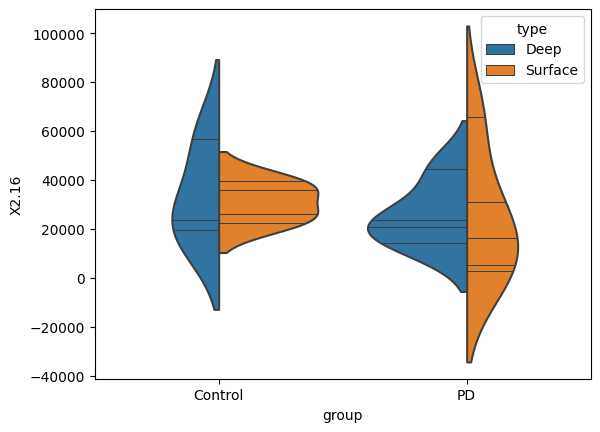

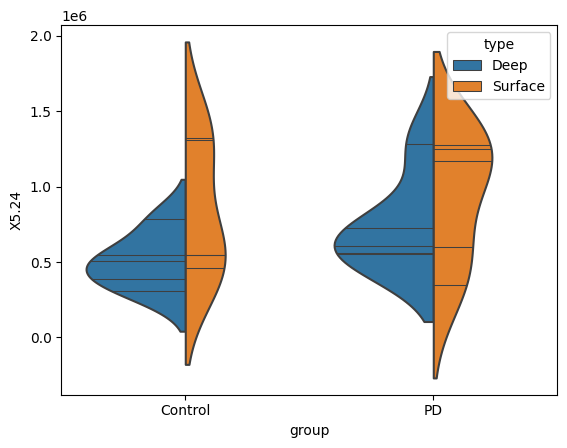

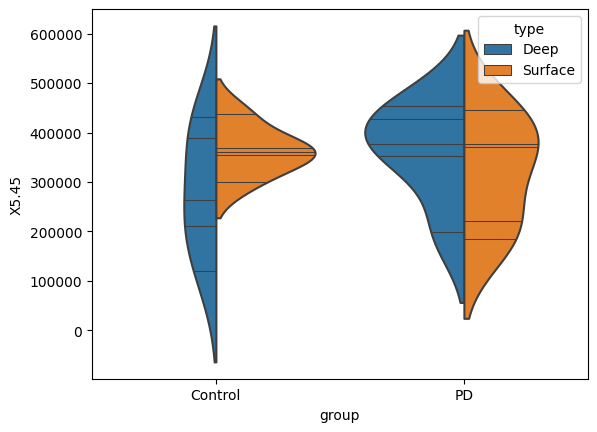

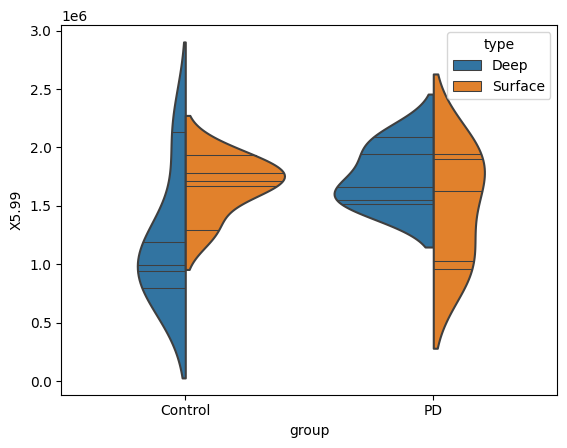

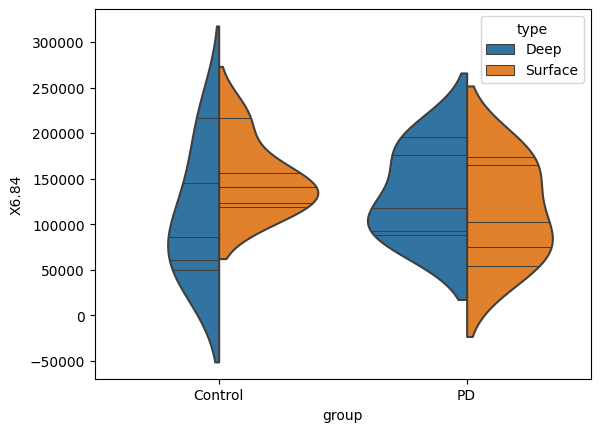

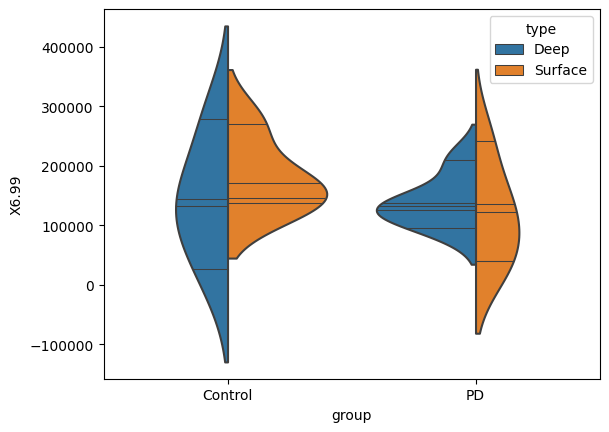

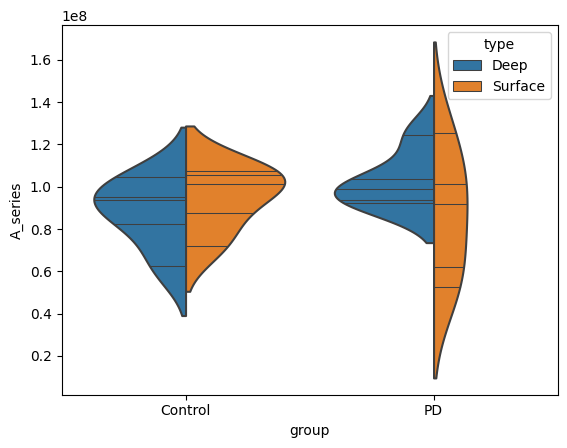

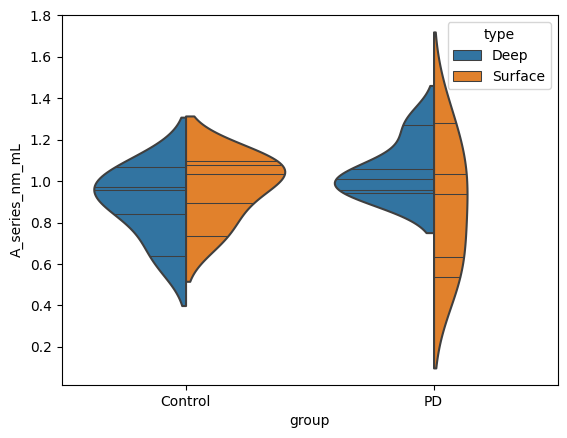

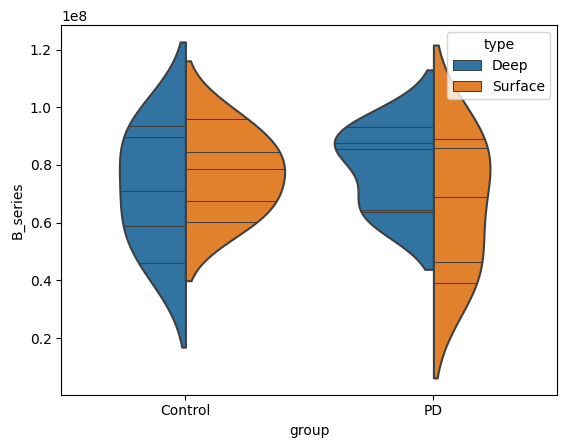

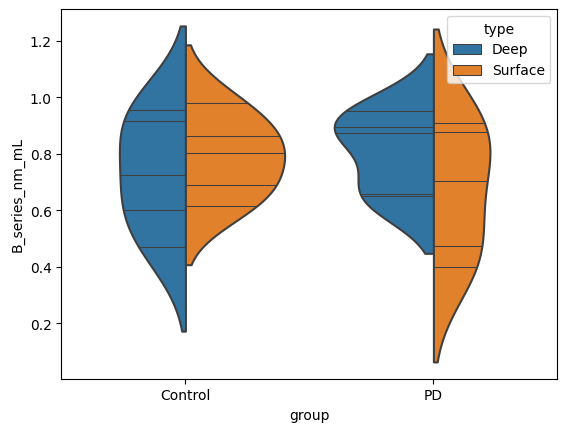

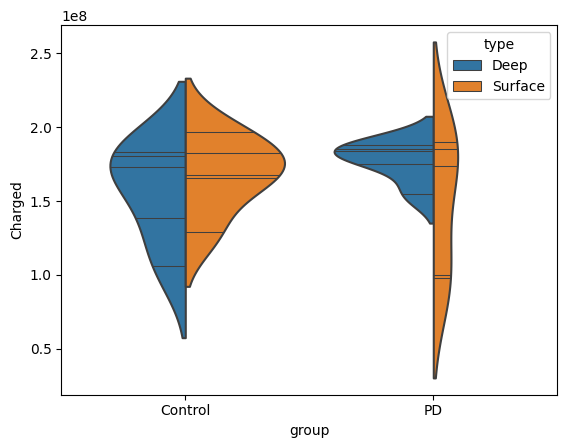

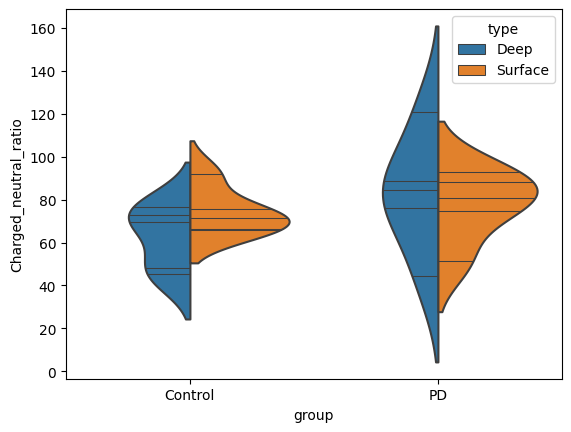

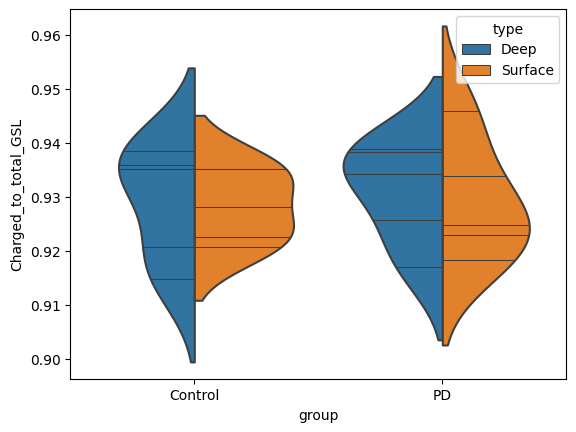

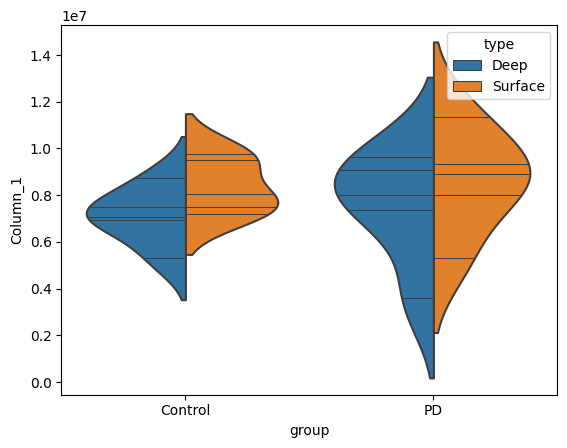

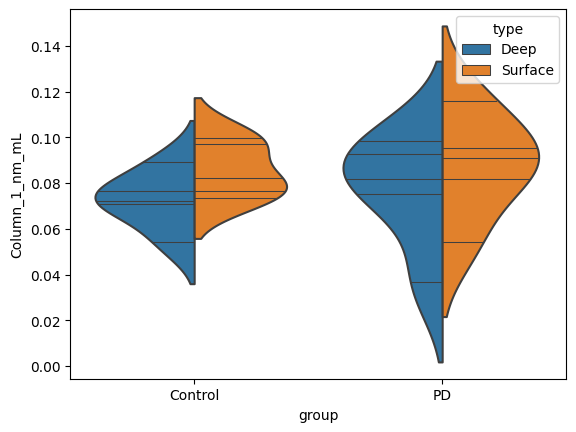

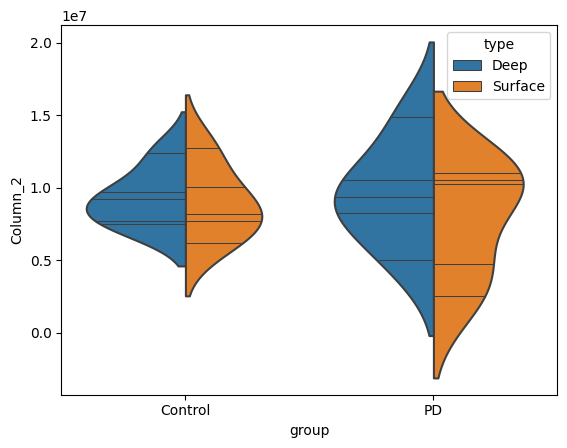

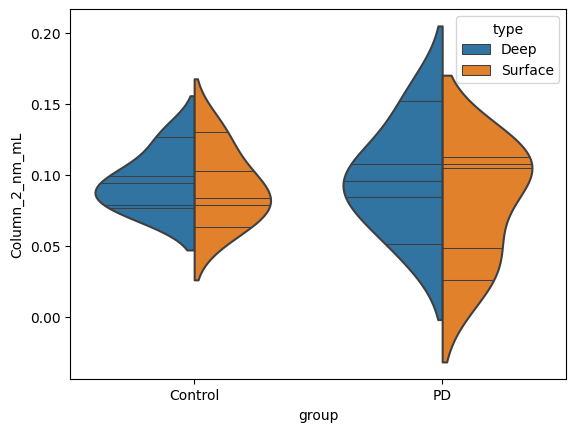

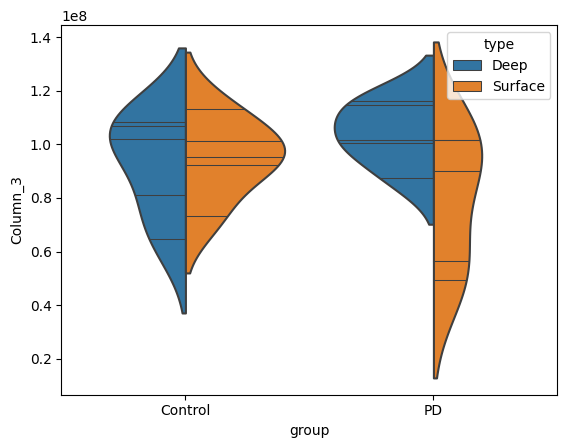

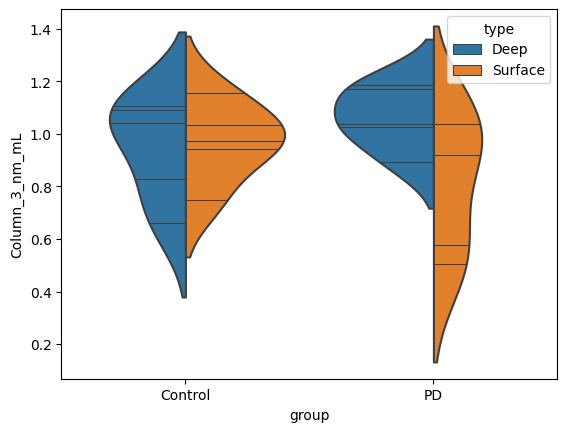

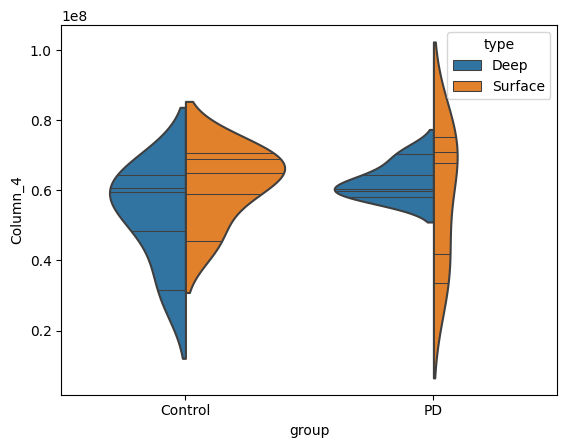

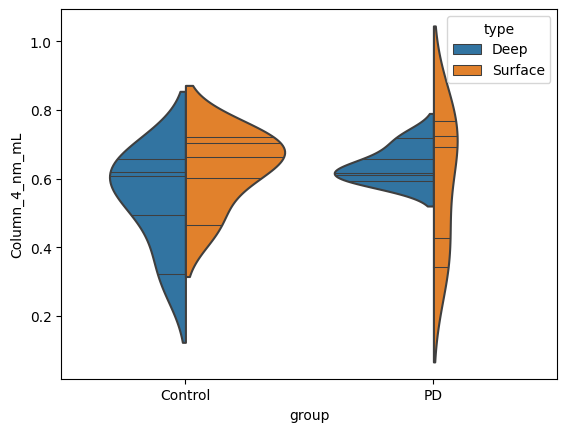

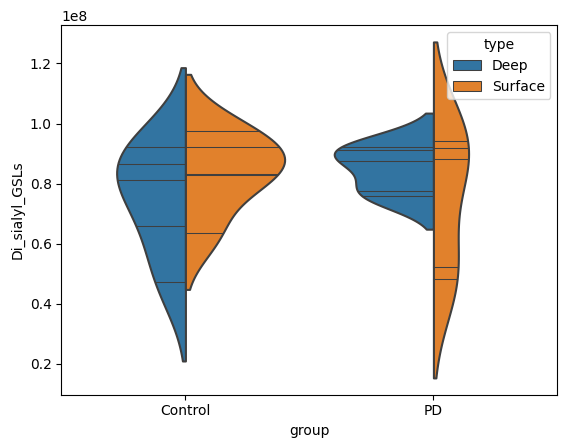

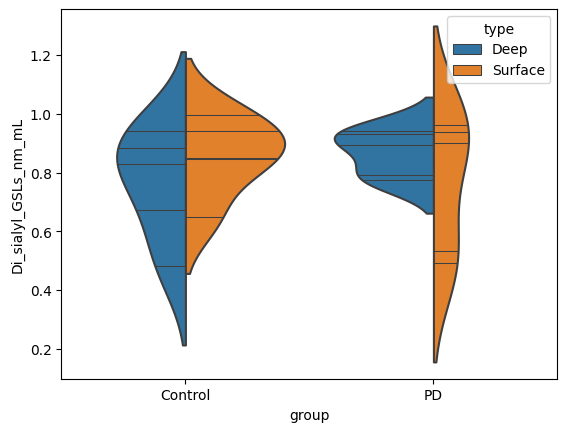

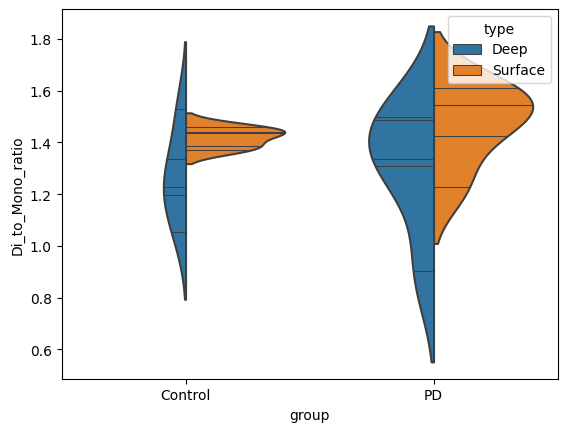

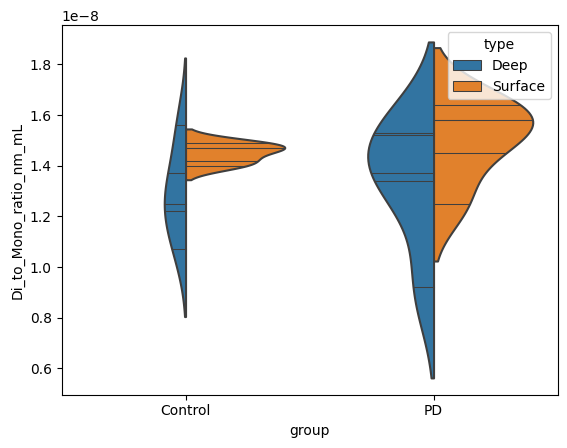

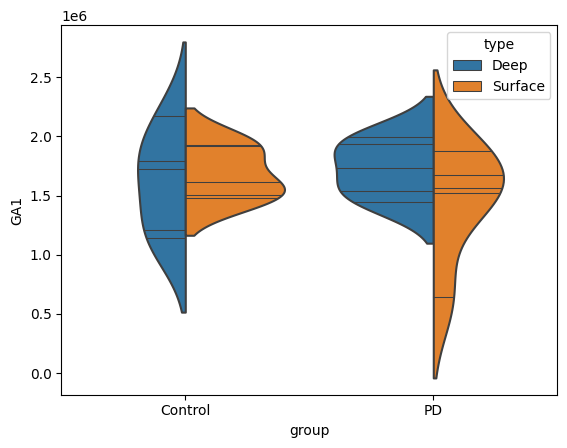

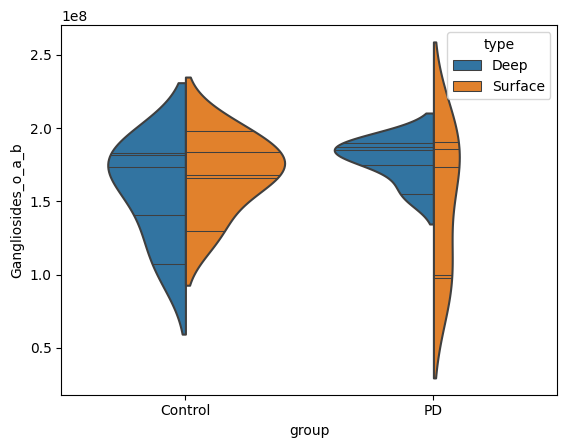

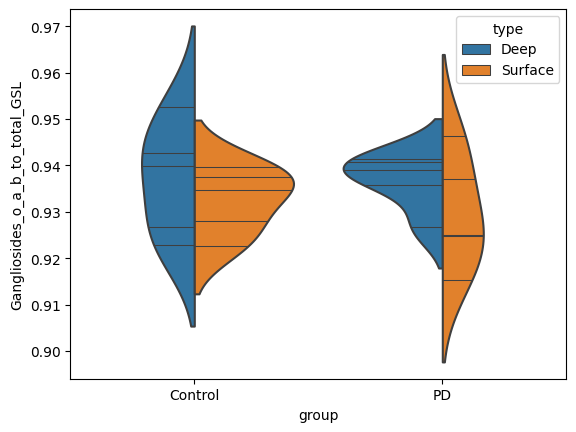

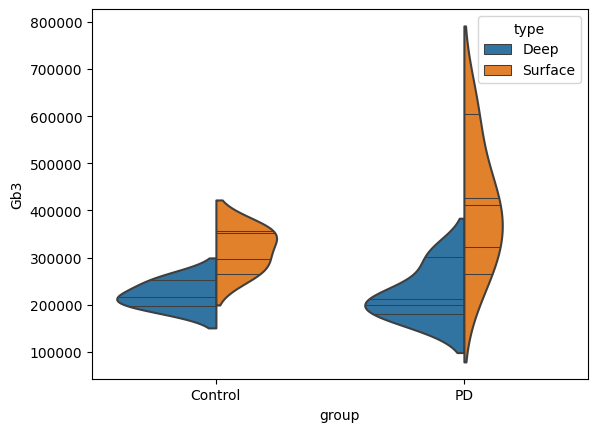

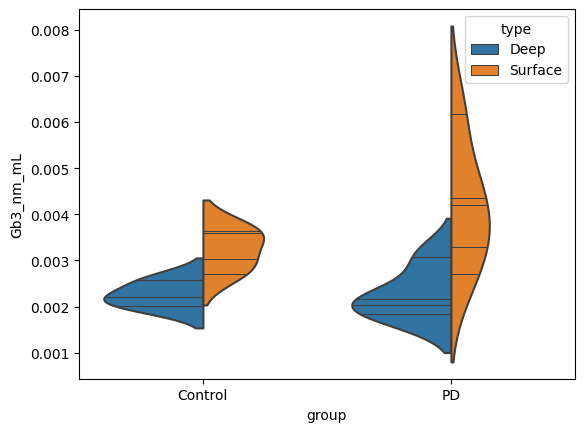

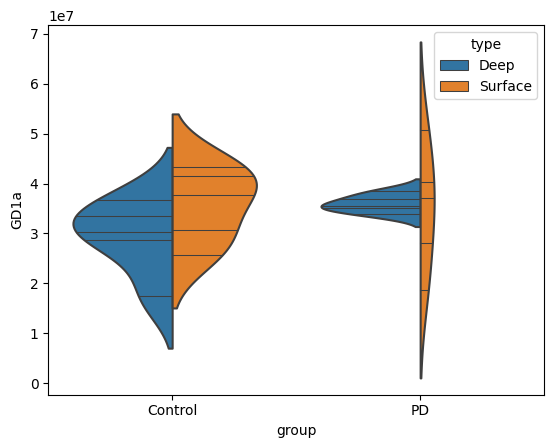

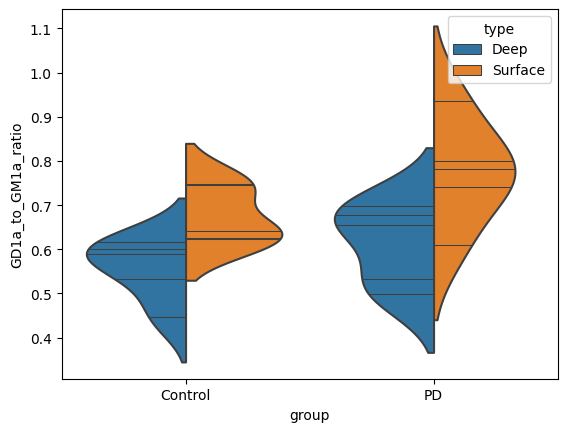

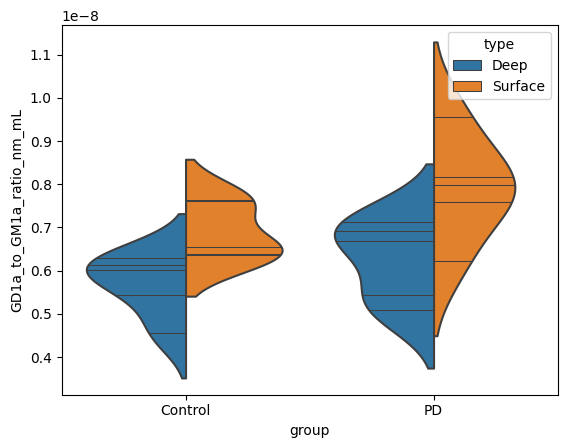

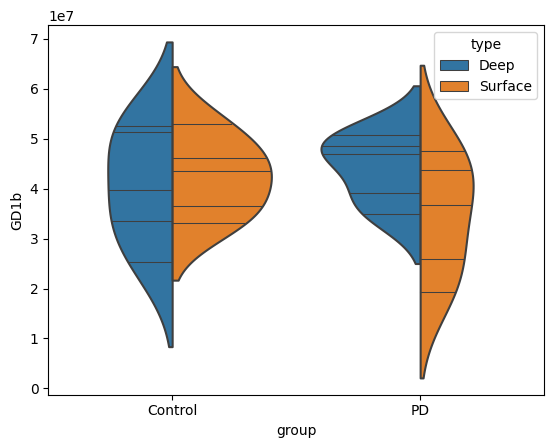

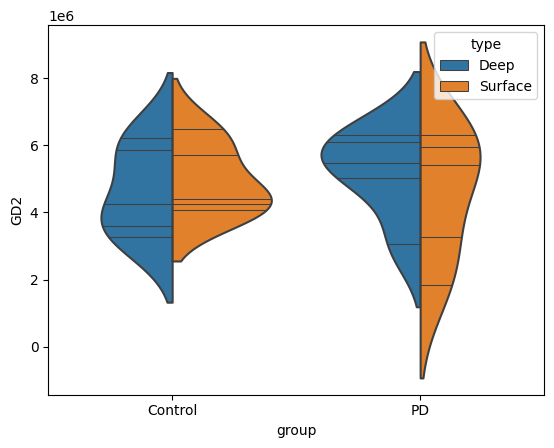

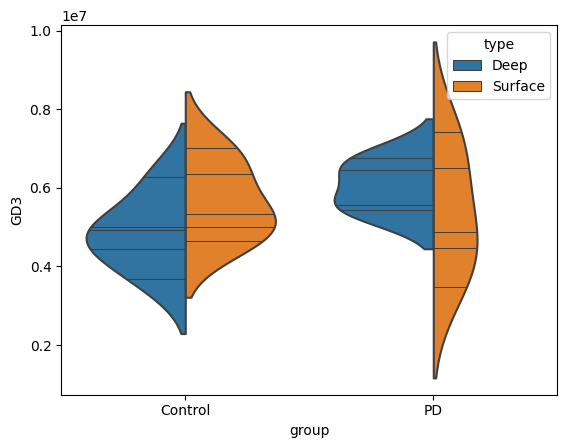

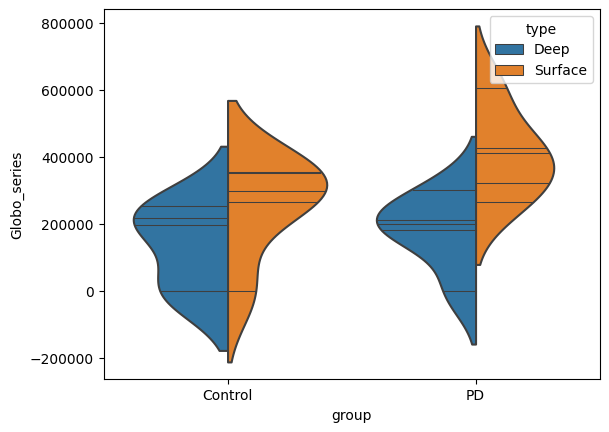

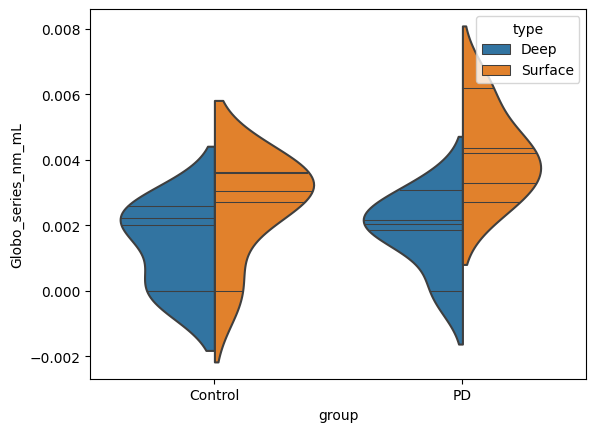

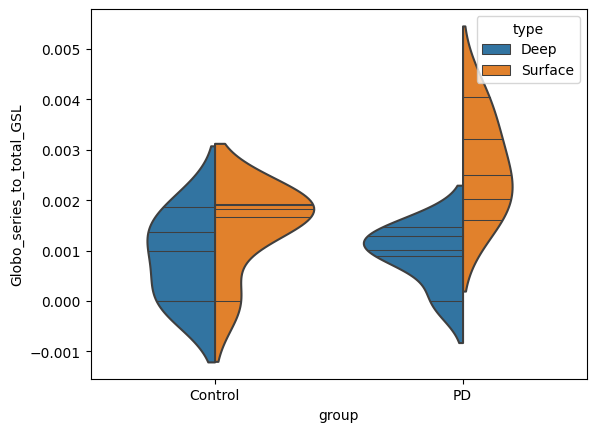

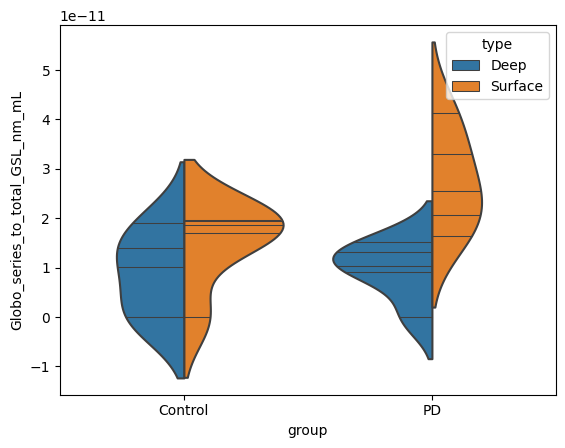

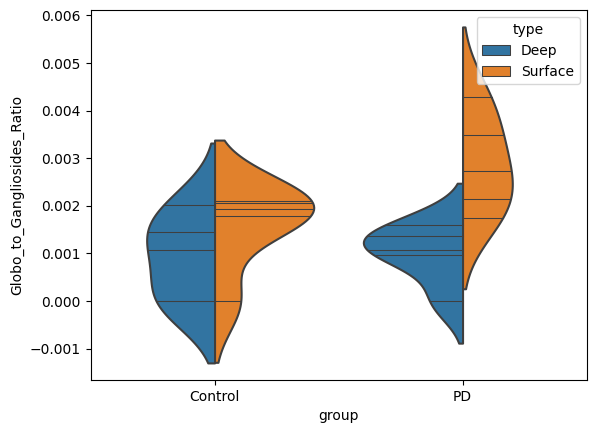

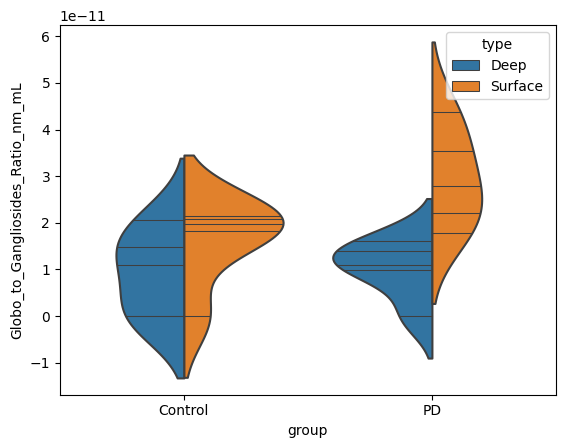

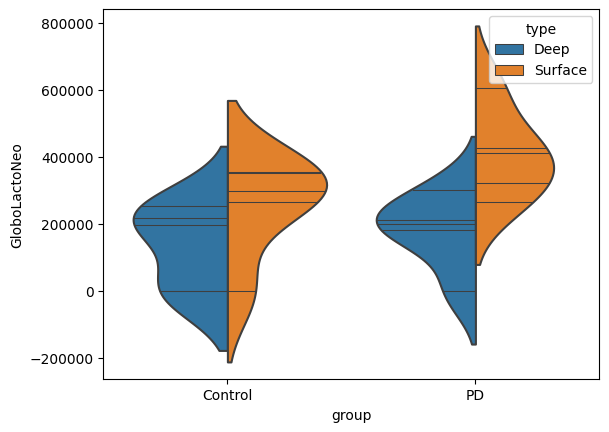

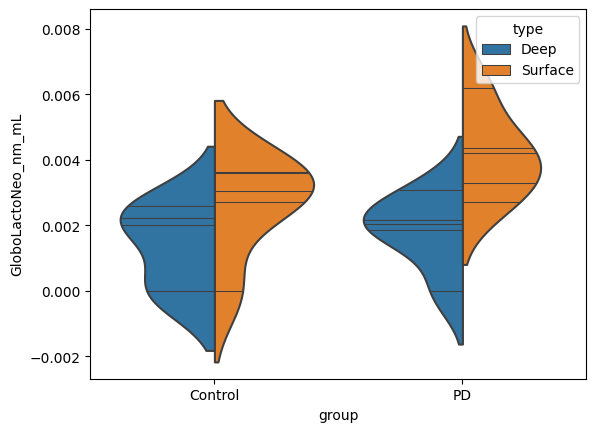

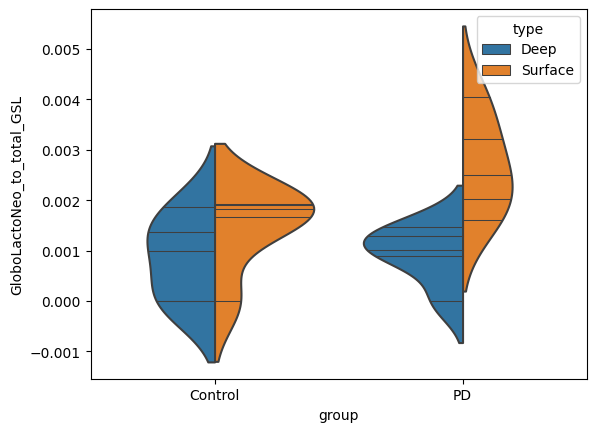

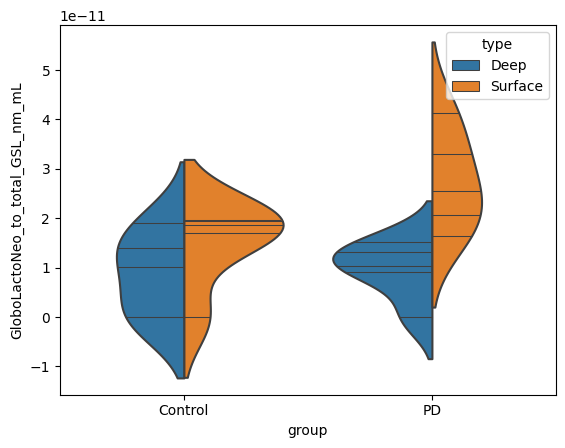

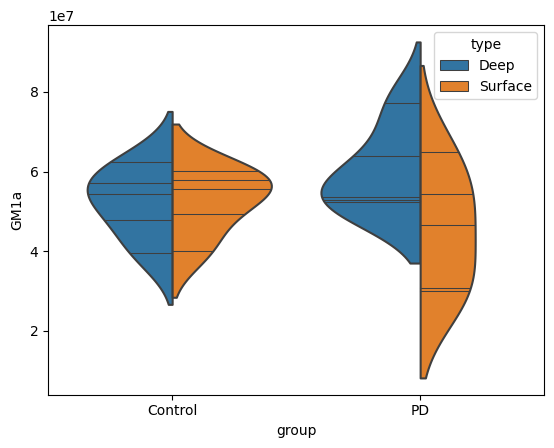

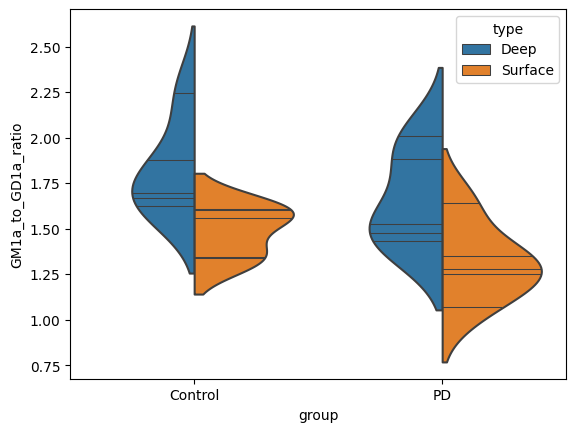

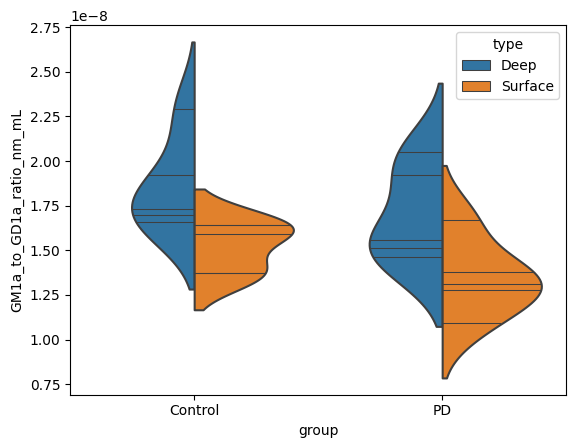

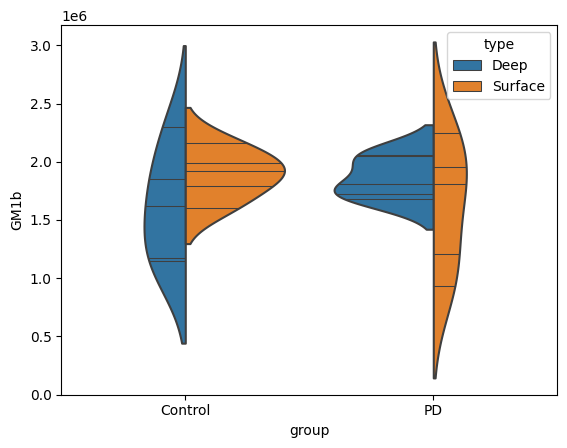

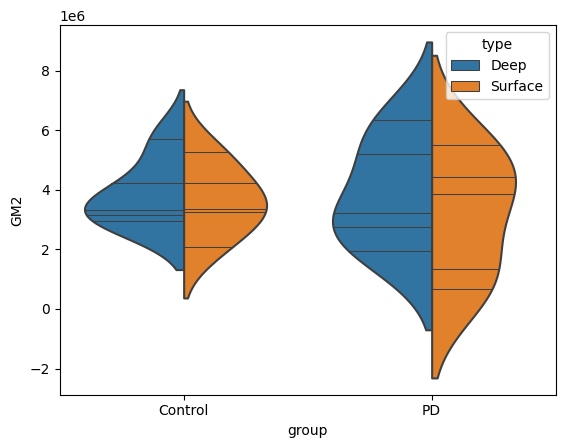

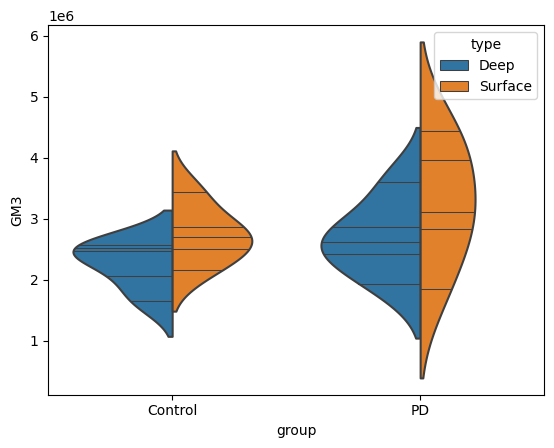

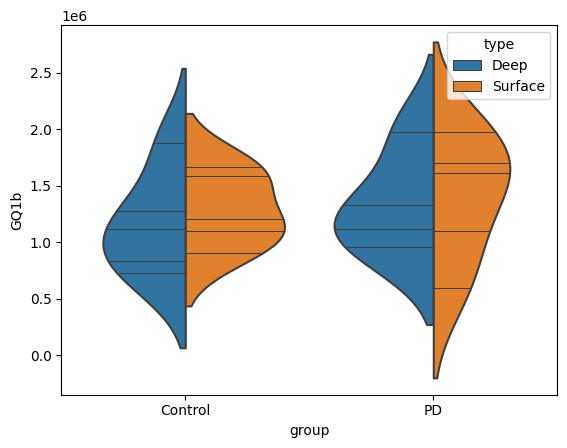

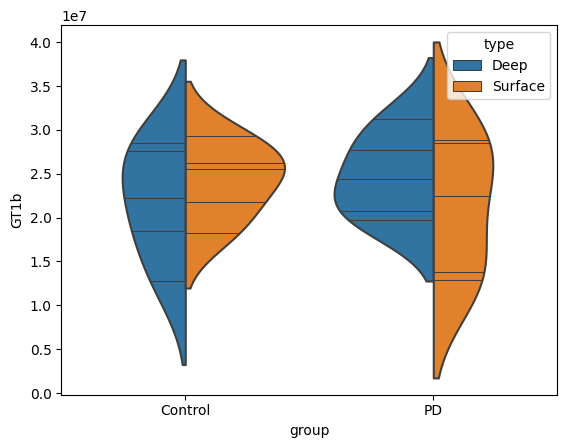

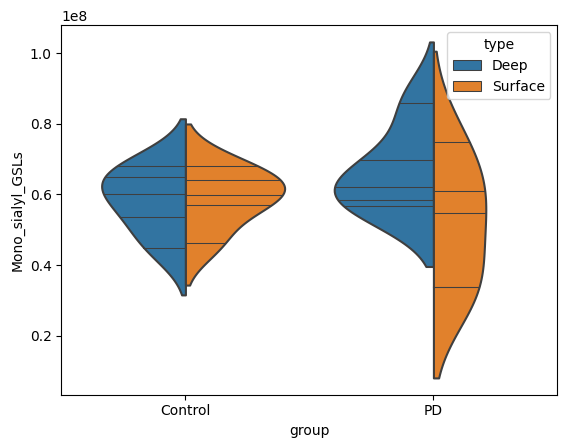

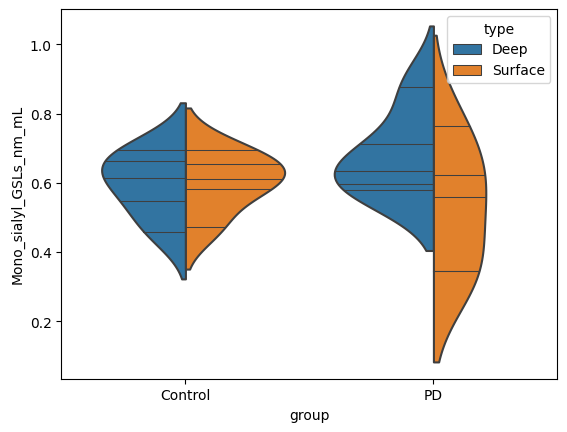

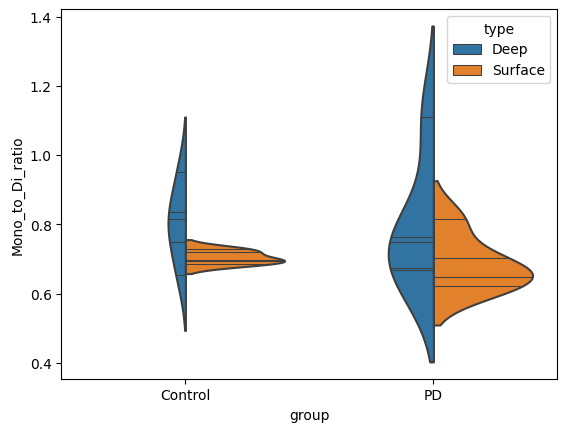

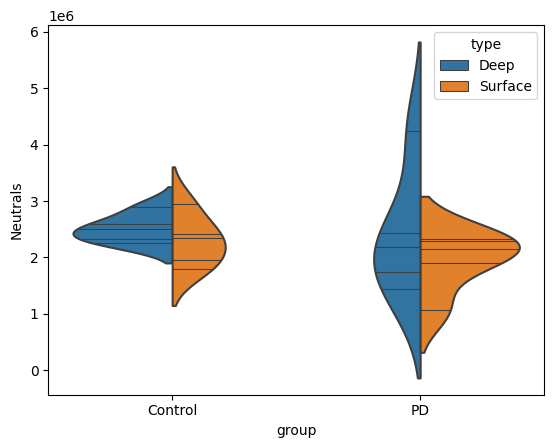

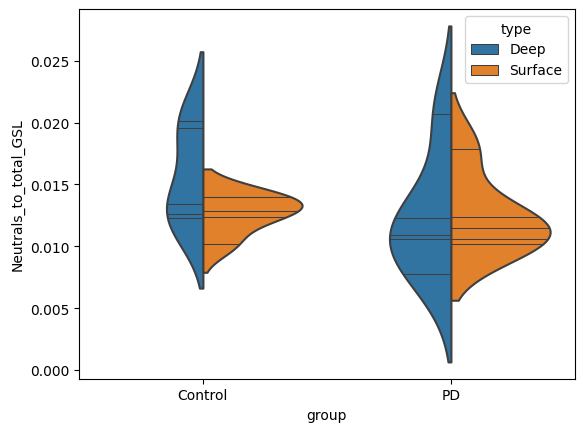

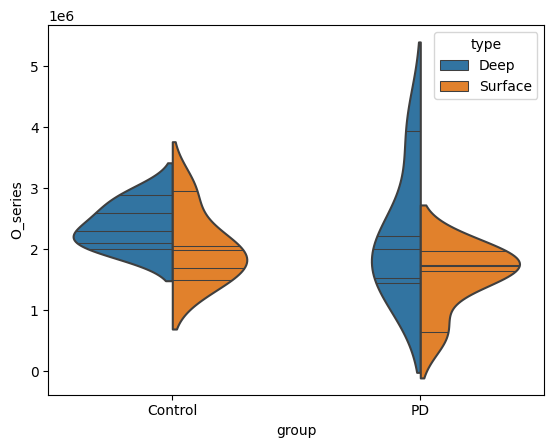

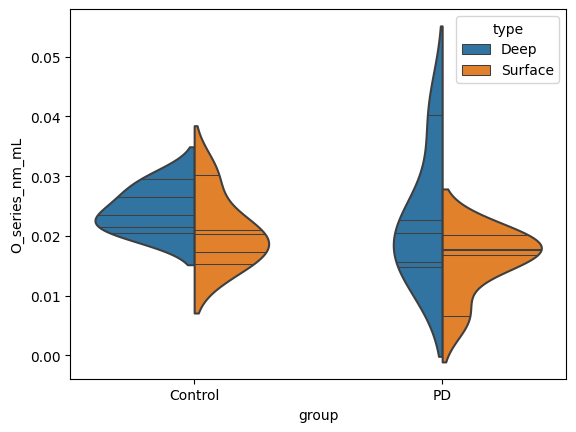

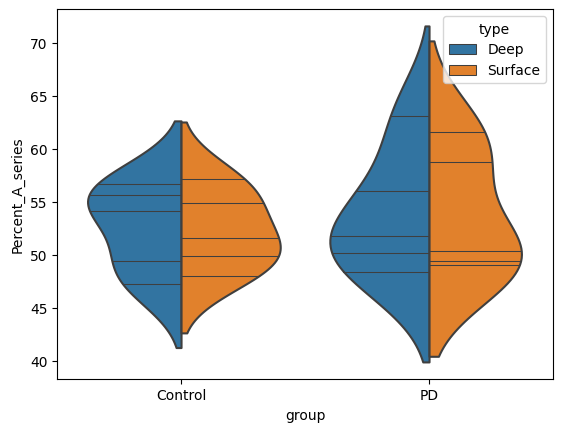

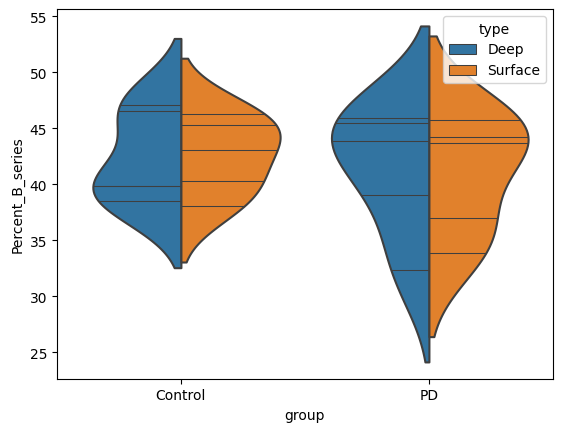

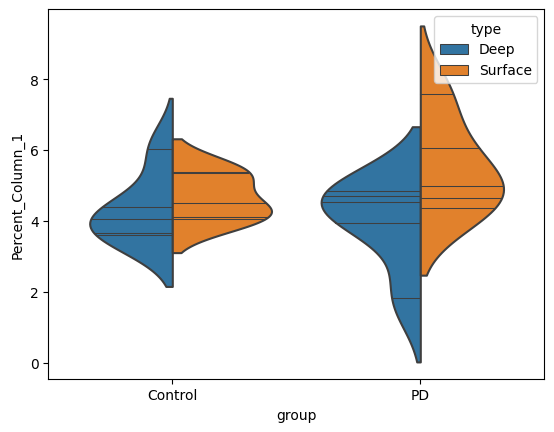

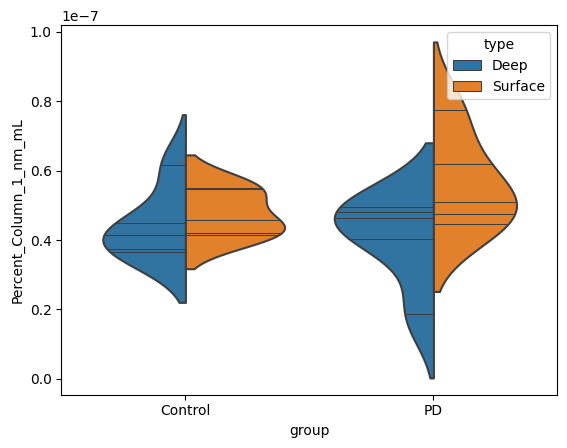

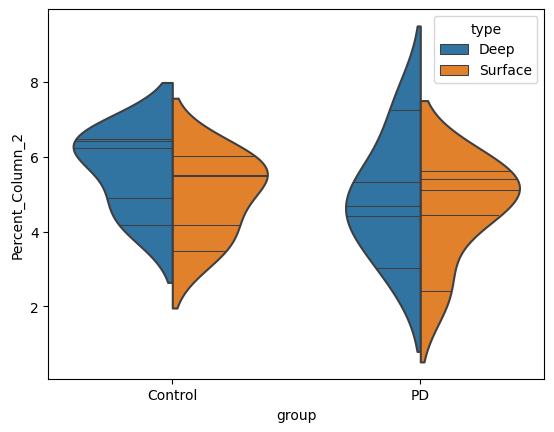

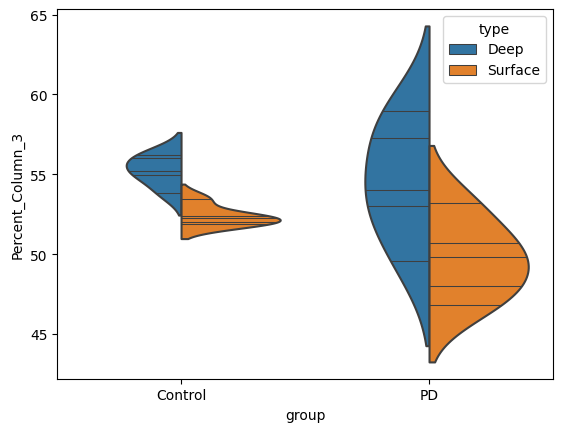

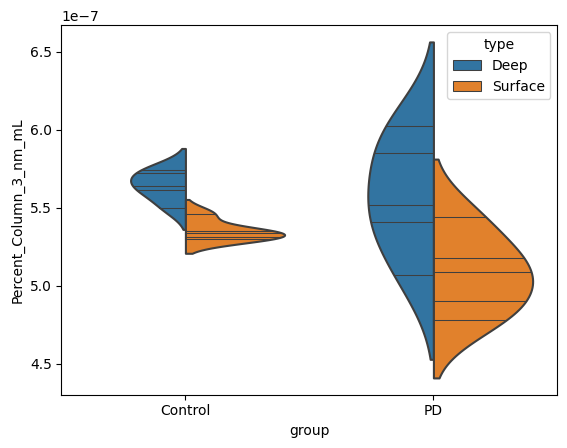

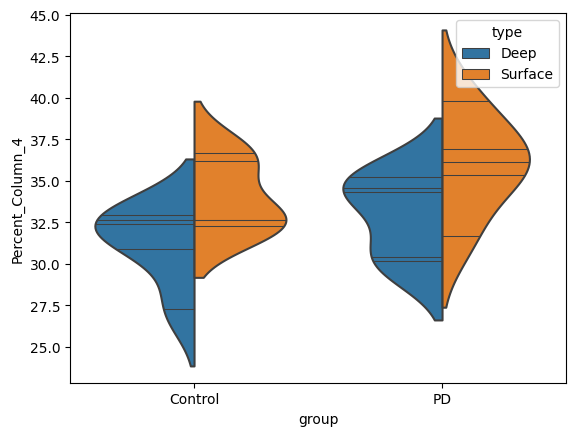

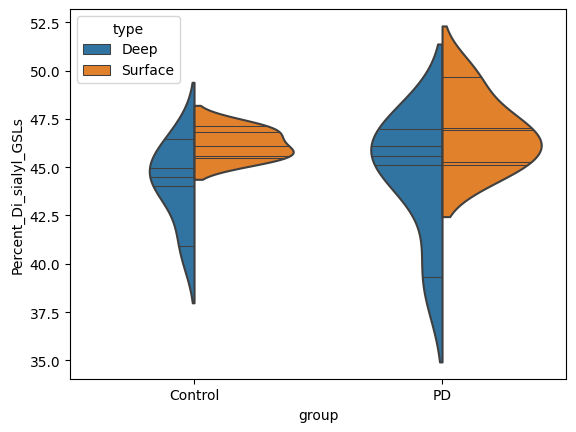

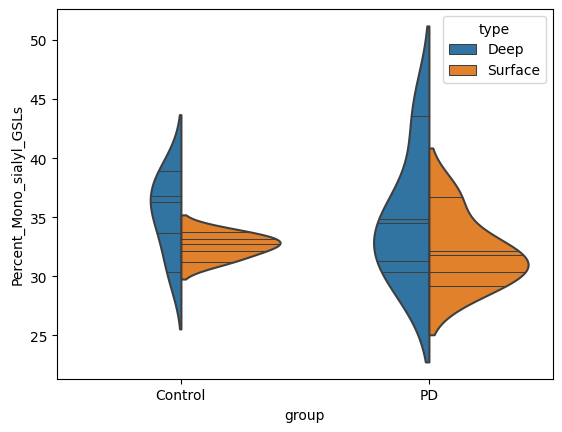

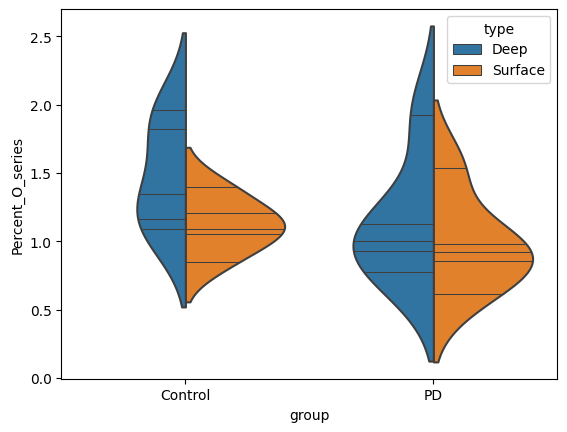

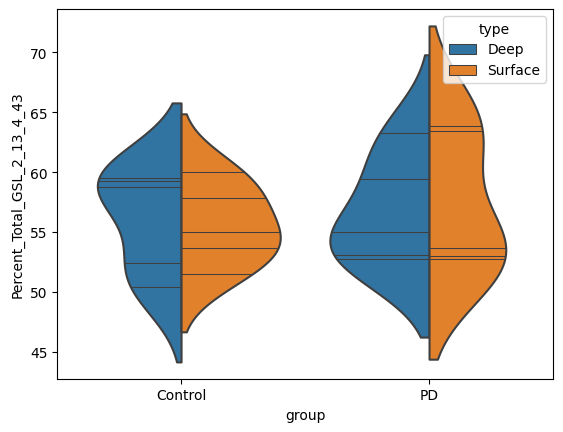

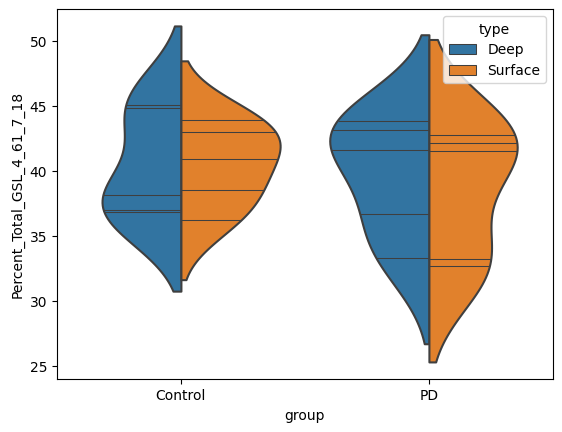

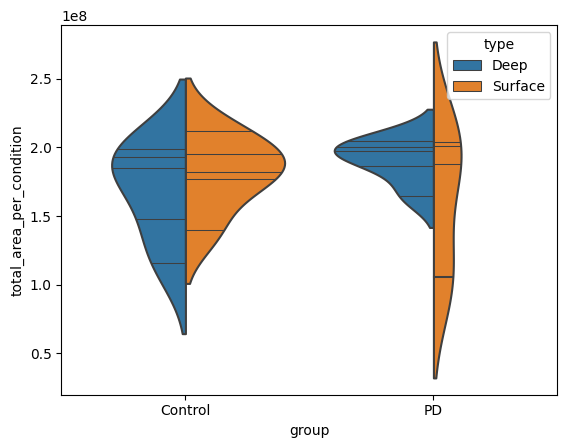

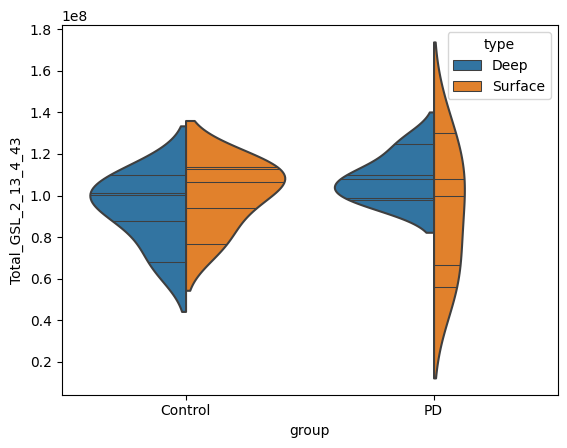

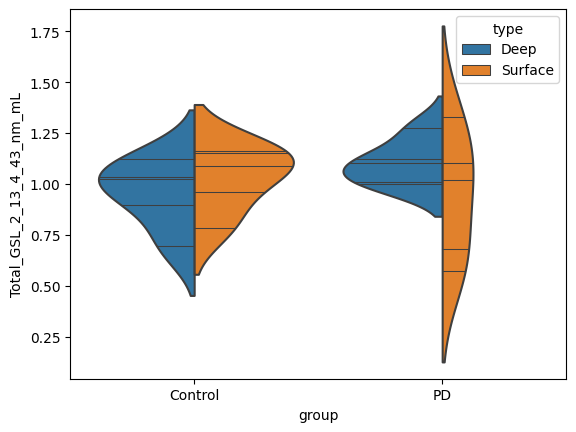

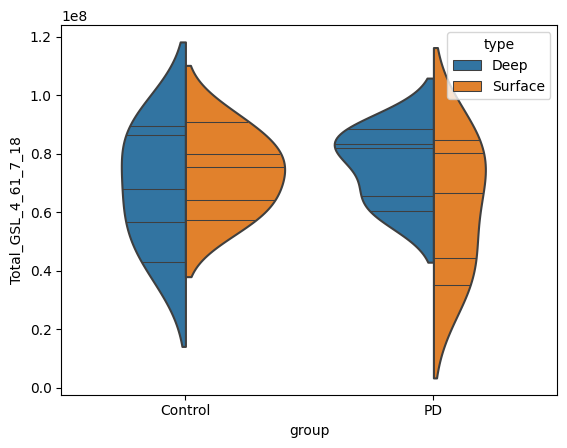

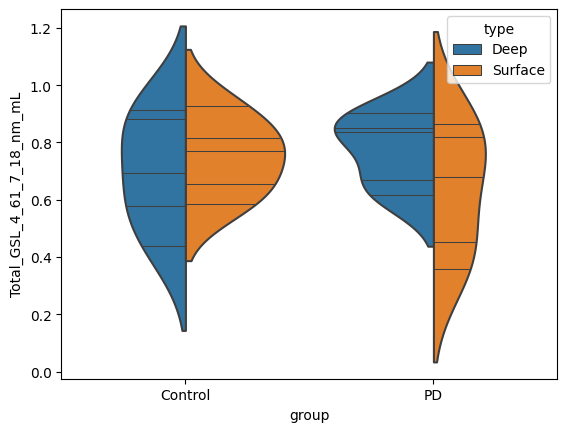

In [2]:
for cat in list(sig.index):
    sns.violinplot(x = df["group"], y = df[cat], hue = df["type"], split = True, inner="stick")
    #sns.swarmplot(x = df["group"], y = df[cat], hue = df["type"])
    plt.show()